# Dataset Comparison: Local SWE-bench vs. Exgentic SWE-bench

Compares all 4 KV-cache policies (`Baseline Full LRU`, `Full-Conv Oracle`, `Naive Paged LRU`, `Paged Oracle (JIT)`) at `48 GB` and `64 GB` HBM (`n=40`, `λ=0.15`, `max_time=5000.0 s`) across:
1. **Local SWE-bench** (`data/swebench_traces.jsonl`, OpenHands): short tool waits (`p50 = 0.02 s`, `mean = 0.79 s`, `~2.5%` tool share).
2. **Exgentic SWE-bench** (`data/external_traces/exgentic_swebench.jsonl`, `Exgentic/agent-llm-traces`): longer tool waits (`p50 = 1.41 s`, `mean = 7.66 s`, `p95 = 31.76 s`, `~27.6%` tool share).

In [1]:
import multiprocessing
import os
import sys
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()))
os.chdir(str(Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()))

from sim.scheduler_sim import KVGeometry
from sim.verify_evictions import load_openhands_traces
from sim.paged_vs_oracle import POLICY_MAP, run_single_sim

plt.rcParams.update({'figure.dpi': 125, 'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10})
geom = KVGeometry(layers=32)

datasets = [
    ('Local SWE-bench', 'data/swebench_traces.jsonl'),
    ('Exgentic SWE-bench', 'data/external_traces/exgentic_swebench.jsonl'),
]

for label, path in datasets:
    trs = load_openhands_traces(path)
    tt = [it.tool_time for tr in trs for it in tr.iters if it.tool_time > 0]
    pk = [geom.blocks_for_tokens(max(it.ctx_tokens for it in tr.iters)) * geom.bytes_per_block / (1024**3) for tr in trs]
    print(f'{label:20s}: {len(trs):3d} traces | Peak KV med={np.median(pk):.2f}GB max={np.max(pk):.2f}GB | '
          f'Tool wait p50={np.percentile(tt,50):.2f}s mean={np.mean(tt):.2f}s p95={np.percentile(tt,95):.2f}s')

Local SWE-bench     : 300 traces | Peak KV med=3.71GB max=24.41GB | Tool wait p50=0.02s mean=0.79s p95=1.28s
Exgentic SWE-bench  :  79 traces | Peak KV med=4.17GB max=8.26GB | Tool wait p50=3.07s mean=7.53s p95=25.77s


In [2]:
configs = [(64.0, 0.15), (48.0, 0.15)]
policies = [
    ('Baseline Full LRU',  '#64748b'),
    ('Full-Conv Oracle',   '#f59e0b'),
    ('Naive Paged LRU',    '#3b82f6'),
    ('Paged Oracle (JIT)', '#10b981'),
]
n_requests, seed, max_time = 40, 42, 5000.0

tasks = [
    (pname, hbm, rate, n_requests, seed, max_time, path)
    for _, path in datasets
    for hbm, rate in configs
    for pname, _ in policies
]
n_workers = min(len(tasks), os.cpu_count() or 8)
with ProcessPoolExecutor(max_workers=n_workers, mp_context=multiprocessing.get_context('fork')) as ex:
    results = dict(ex.map(run_single_sim, tasks))

hdr = (f"{'Dataset':19s} | {'Cfg':9s} | {'Policy':19s} | {'Done':5s} | {'LastDone':8s} | {'MeanE2E':8s} | "
       f"{'EvictGB':9s} | {'TTFT':7s} | {'TTFTp95':7s} | {'HBM Wait':8s}")
print(hdr)
print('-' * len(hdr))
for dlabel, path in datasets:
    for hbm, rate in configs:
        for pname, _ in policies:
            s = results[(path, hbm, rate, pname)]
            print(f"{dlabel:19s} | {hbm:3.0f}G {rate:.2f} | {pname:19s} | {s['done']:2d}/{s['total_requests']:2d} | "
                  f"{s['makespan_done_s']:6.1f} s | {s['mean_e2e_s']:6.1f} s | {s['total_evicted_gb']:7.1f} G | "
                  f"{s['ttft_mean']:5.2f} s | {s['ttft_p95']:5.2f} s | {s['hbm_wait_mean']:6.2f} s")
        print('-' * len(hdr))

Dataset             | Cfg       | Policy              | Done  | LastDone | MeanE2E  | EvictGB   | TTFT    | TTFTp95 | HBM Wait
------------------------------------------------------------------------------------------------------------------------------
Local SWE-bench     |  64G 0.15 | Baseline Full LRU   | 39/40 | 3887.4 s | 1110.9 s |   908.3 G |  5.45 s | 11.03 s |   5.19 s
Local SWE-bench     |  64G 0.15 | Full-Conv Oracle    | 39/40 | 3886.9 s | 1116.1 s |   888.6 G |  5.25 s |  9.05 s |   5.00 s
Local SWE-bench     |  64G 0.15 | Naive Paged LRU     | 39/40 | 3868.2 s | 1108.0 s |   778.6 G |  5.31 s | 13.11 s |   5.05 s
Local SWE-bench     |  64G 0.15 | Paged Oracle (JIT)  | 39/40 | 3870.1 s | 1113.4 s |   622.3 G |  5.43 s | 11.39 s |   5.16 s
------------------------------------------------------------------------------------------------------------------------------
Local SWE-bench     |  48G 0.15 | Baseline Full LRU   | 39/40 | 4115.5 s | 1220.5 s |  2036.9 G |  9.91 s | 30.

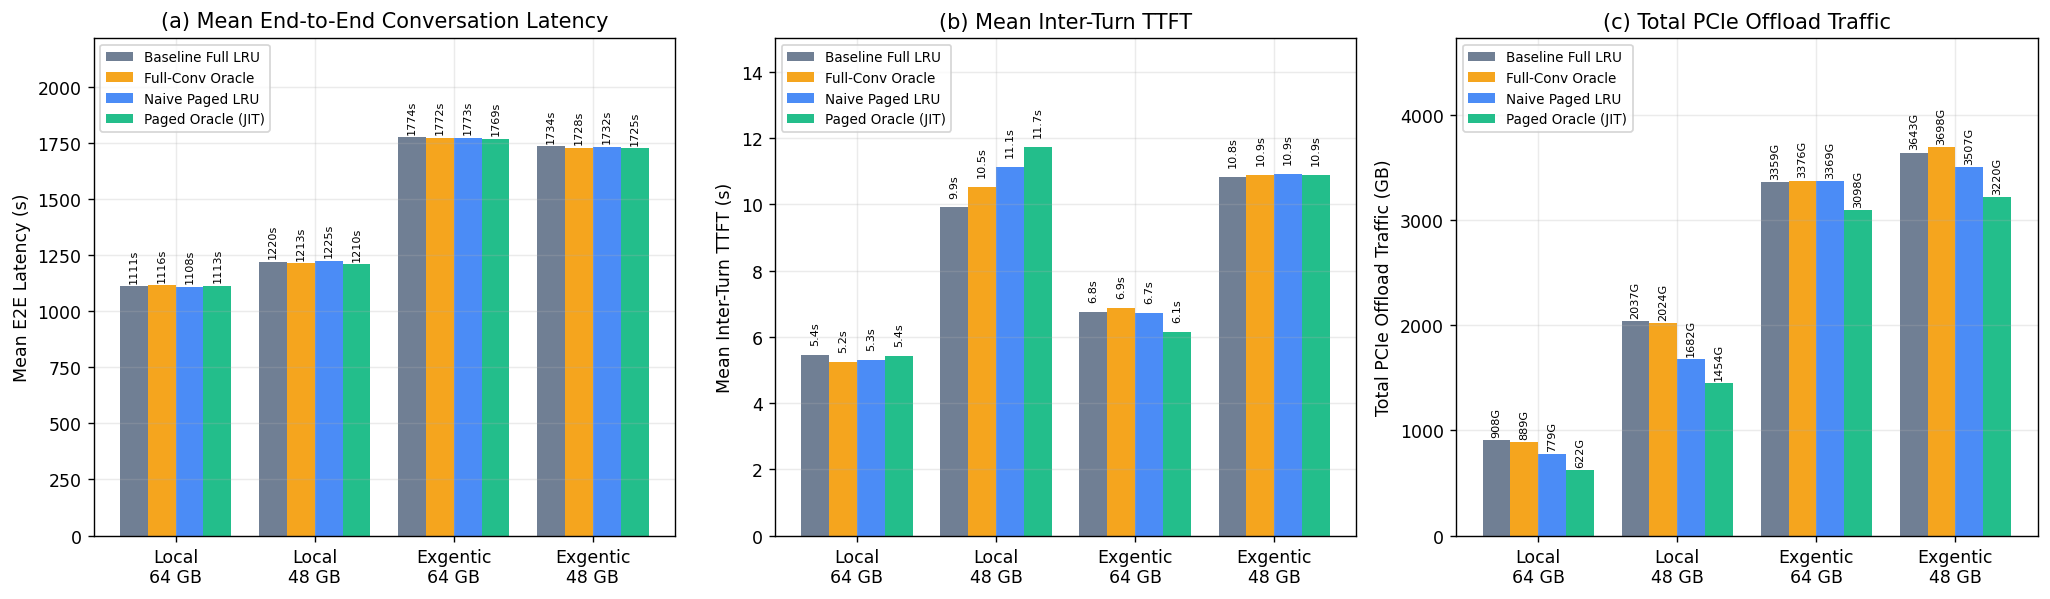

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.9))
groups = [(dlabel, path, hbm, rate) for dlabel, path in datasets for hbm, rate in configs]
x = np.arange(len(groups))
x_labels = [f"{d.replace(' SWE-bench','')}\n{h:.0f} GB" for d, _, h, _ in groups]
w = 0.20
offsets = [-1.5*w, -0.5*w, 0.5*w, 1.5*w]

for off, (pname, col) in zip(offsets, policies):
    vals = [results[(p, h, r, pname)]['mean_e2e_s'] for _, p, h, r in groups]
    axes[0].bar(x + off, vals, w, label=pname, color=col, alpha=0.92)
    for xi, v in zip(x, vals):
        axes[0].text(xi + off, v + 15, f'{v:.0f}s', ha='center', va='bottom', fontsize=6.5, rotation=90)
axes[0].set_xticks(x); axes[0].set_xticklabels(x_labels)
axes[0].set_ylabel('Mean E2E Latency (s)'); axes[0].set_title('(a) Mean End-to-End Conversation Latency')
axes[0].set_ylim(0, max(results[(p, h, r, pn)]['mean_e2e_s'] for _, p, h, r in groups for pn, _ in policies) * 1.25)
axes[0].legend(loc='upper left', fontsize=7.8, frameon=True)

for off, (pname, col) in zip(offsets, policies):
    vals = [results[(p, h, r, pname)]['ttft_mean'] for _, p, h, r in groups]
    axes[1].bar(x + off, vals, w, label=pname, color=col, alpha=0.92)
    for xi, v in zip(x, vals):
        axes[1].text(xi + off, v + 0.3, f'{v:.1f}s', ha='center', va='bottom', fontsize=6.5, rotation=90)
axes[1].set_xticks(x); axes[1].set_xticklabels(x_labels)
axes[1].set_ylabel('Mean Inter-Turn TTFT (s)'); axes[1].set_title('(b) Mean Inter-Turn TTFT')
axes[1].set_ylim(0, max(results[(p, h, r, pn)]['ttft_mean'] for _, p, h, r in groups for pn, _ in policies) * 1.28)
axes[1].legend(loc='upper left', fontsize=7.8, frameon=True)

for off, (pname, col) in zip(offsets, policies):
    vals = [results[(p, h, r, pname)]['total_evicted_gb'] for _, p, h, r in groups]
    axes[2].bar(x + off, vals, w, label=pname, color=col, alpha=0.92)
    for xi, v in zip(x, vals):
        axes[2].text(xi + off, v + 30, f'{v:.0f}G', ha='center', va='bottom', fontsize=6.5, rotation=90)
axes[2].set_xticks(x); axes[2].set_xticklabels(x_labels)
axes[2].set_ylabel('Total PCIe Offload Traffic (GB)'); axes[2].set_title('(c) Total PCIe Offload Traffic')
axes[2].set_ylim(0, max(results[(p, h, r, pn)]['total_evicted_gb'] for _, p, h, r in groups for pn, _ in policies) * 1.28)
axes[2].legend(loc='upper left', fontsize=7.8, frameon=True)

plt.tight_layout()
plt.show()

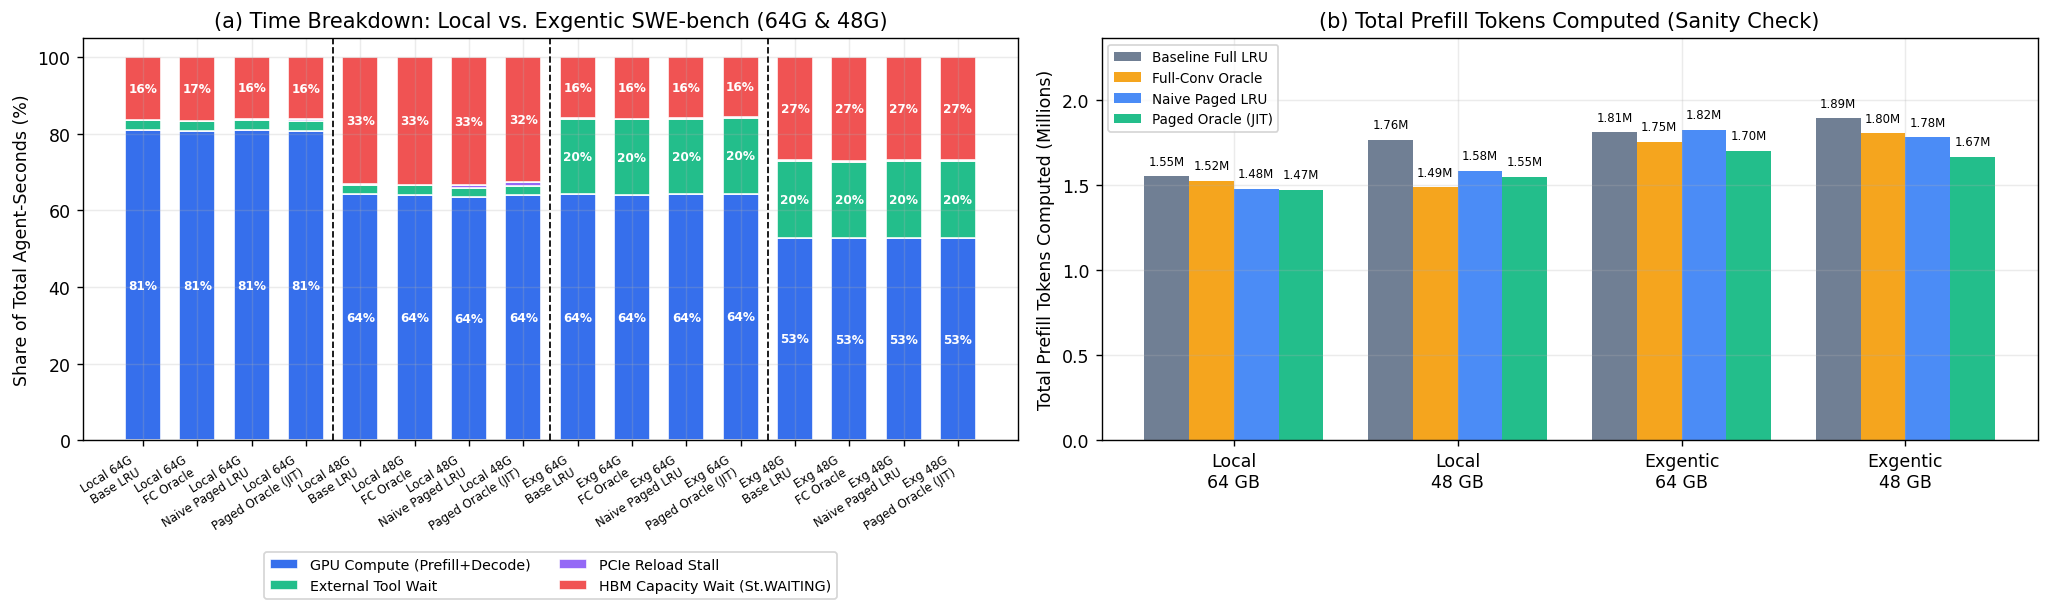

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16.5, 5.2))

bar_labels, decode_pct, tool_pct, stall_pct, wait_pct = [], [], [], [], []
for dlabel, path, hbm, rate in groups:
    short_d = 'Local' if 'Local' in dlabel else 'Exg'
    for pname, _ in policies:
        s = results[(path, hbm, rate, pname)]
        ss = s['state_seconds']
        tot = max(1e-9, sum(ss.values()))
        bar_labels.append(f"{short_d} {hbm:.0f}G\n{pname.replace('Full-Conv ', 'FC ').replace('Baseline Full ', 'Base ')}")
        decode_pct.append(100.0 * (ss['DECODE'] + ss['PREFILL']) / tot)
        tool_pct.append(100.0 * ss['TOOL'] / tot)
        stall_pct.append(100.0 * ss['STALL'] / tot)
        wait_pct.append(100.0 * ss['WAITING'] / tot)

xb = np.arange(len(bar_labels))
bottom = np.zeros(len(bar_labels))
for lbl, vals, col in [
    ('GPU Compute (Prefill+Decode)', decode_pct, '#2563eb'),
    ('External Tool Wait', tool_pct, '#10b981'),
    ('PCIe Reload Stall', stall_pct, '#8b5cf6'),
    ('HBM Capacity Wait (St.WAITING)', wait_pct, '#ef4444'),
]:
    arr = np.array(vals)
    axes[0].bar(xb, arr, width=0.66, bottom=bottom, label=lbl, color=col, alpha=0.92, edgecolor='white')
    for xi, v, b in zip(xb, arr, bottom):
        if v >= 7.0:
            axes[0].text(xi, b + v / 2.0, f'{v:.0f}%', ha='center', va='center', color='white', fontsize=7.0, fontweight='bold')
    bottom += arr
for sep in [3.5, 7.5, 11.5]:
    axes[0].axvline(sep, color='black', linestyle='--', lw=1.0)
axes[0].set_xticks(xb)
axes[0].set_xticklabels(bar_labels, fontsize=6.8, rotation=32, ha='right')
axes[0].set_ylim(0, 105)
axes[0].set_ylabel('Share of Total Agent-Seconds (%)')
axes[0].set_title('(a) Time Breakdown: Local vs. Exgentic SWE-bench (64G & 48G)')
axes[0].legend(loc='upper center', bbox_to_anchor=(0.5, -0.26), ncol=2, frameon=True, fontsize=8.2)

for off, (pname, col) in zip(offsets, policies):
    vals = [results[(p, h, r, pname)]['total_prefill_tokens'] / 1e6 for _, p, h, r in groups]
    axes[1].bar(x + off, vals, w, label=pname, color=col, alpha=0.92)
    for xi, v in zip(x, vals):
        axes[1].text(xi + off, v + 0.05, f'{v:.2f}M', ha='center', va='bottom', fontsize=6.8)
axes[1].set_xticks(x); axes[1].set_xticklabels(x_labels)
axes[1].set_ylabel('Total Prefill Tokens Computed (Millions)')
axes[1].set_title('(b) Total Prefill Tokens Computed (Sanity Check)')
axes[1].set_ylim(0, max(results[(p, h, r, pn)]['total_prefill_tokens'] / 1e6 for _, p, h, r in groups for pn, _ in policies) * 1.25)
axes[1].legend(loc='upper left', fontsize=7.8, frameon=True)

plt.tight_layout()
plt.show()